# Pruebas de Hipótesis para una Población
## Enfoque "A Pie" (Paso a Paso) vs. Funciones Predefinidas en Python

Este notebook presenta de forma didáctica y rigurosa cuatro pruebas de hipótesis paramétricas fundamentales para una sola población, contrastando en cada caso dos aproximaciones:
1. **Cálculo "a pie" (paso a paso)**: deduciendo el estadístico de prueba a partir de su definición matemática, calculando los errores estándar, los valores críticos y obteniendo el p-valor exacto mediante funciones de distribución acumulada y de supervivencia de `scipy.stats` (`norm`, `t`, `chi2`).
2. **Uso de funciones predefinidas**: empleando funciones especializadas y empaquetadas del ecosistema de Python (`scipy.stats.ttest_1samp`, `statsmodels.stats.proportion.proportions_ztest`, etc.).

---

### Casos Desarrollados:
1. **Media con Desviación Estándar Conocida ($\sigma$ conocida)** — Prueba $Z$
2. **Media con Desviación Estándar Desconocida ($\sigma$ desconocida)** — Prueba $t$ de Student
3. **Proporción Poblacional ($p$)** — Prueba $Z$ para proporciones (y contraste con prueba binomial exacta)
4. **Varianza Poblacional ($\sigma^2$)** — Prueba $\chi^2$ (Chi-cuadrada)

---

### Marco Metodológico de 5 Pasos
Toda prueba estadística en este notebook se estructura según el protocolo formal de inferencia:
1. **Paso 1:** Formular las hipótesis nula ($H_0$) y alternativa ($H_A$).
2. **Paso 2:** Fijar el nivel de significancia $\alpha$ (fijado en $\alpha = 0.05$ como estándar de referencia).
3. **Paso 3:** Definir el estadístico de prueba y su distribución muestral bajo $H_0$.
4. **Paso 4:** Establecer la regla de decisión (región crítica y regla del p-valor).
5. **Paso 5:** Calcular con los datos muestrales, tomar la decisión e interpretarla en el contexto del problema de ingeniería.


In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.weightstats import ztest as sm_ztest

# Estilos visuales para gráficos claros y legibles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 4.2)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.precision', 5)

print("Entorno estadístico configurado correctamente.")


Entorno estadístico configurado correctamente.


---

## 1. Media Poblacional con Desviación Estándar Conocida ($\sigma$ conocida) — Prueba $Z$

### 1.1 Contexto del Problema e Hipótesis
En una plataforma en la nube, la latencia de un servicio de autenticación tiene una desviación estándar histórica bien documentada de $\sigma = 15.0\text{ ms}$ (determinada a partir de telemetría consolidada sobre millones de peticiones).

Tras desplegar un parche en la base de datos, el equipo desea contrastar si la latencia promedio poblacional sigue siendo igual al valor de referencia de $\mu_0 = 120.0\text{ ms}$ o si ha cambiado:

$$H_0: \mu = 120.0\text{ ms}$$
$$H_A: \mu \neq 120.0\text{ ms} \quad (\text{prueba bilateral})$$

Nivel de significancia: $\alpha = 0.05$.


In [2]:
# Generación sintética del dataset para el Caso 1
np.random.seed(42)
n_z = 45                 # Tamaño de muestra
mu_0_z = 120.0           # Valor de referencia bajo H0
sigma_conocida = 15.0    # Desviación estándar poblacional CONOCIDA

# Simulación de la muestra (con media real ligeramente mayor para el ejemplo)
latencias_known = stats.norm.rvs(loc=124.8, scale=sigma_conocida, size=n_z, random_state=42)
df_z = pd.DataFrame({'latencia_ms': latencias_known})

media_muestral_z = df_z['latencia_ms'].mean()
std_muestral_z = df_z['latencia_ms'].std(ddof=1)

print(f"--- Muestra Caso 1 (n = {n_z}) ---")
print(f"Media muestral (x̄):       {media_muestral_z:.4f} ms")
print(f"Desviación muestral (s):  {std_muestral_z:.4f} ms (no se usa en la prueba Z con σ conocida)")
print(f"Desviación conocida (σ):   {sigma_conocida:.4f} ms")


--- Muestra Caso 1 (n = 45) ---
Media muestral (x̄):       121.5564 ms
Desviación muestral (s):  13.9542 ms (no se usa en la prueba Z con σ conocida)
Desviación conocida (σ):   15.0000 ms


### 1.2 Cálculo "A Pie" (Paso a Paso)
Cuando la varianza poblacional $\sigma^2$ es conocida, el estadístico de prueba exacto sigue una distribución normal estándar:
$$Z_{\text{calc}} = \frac{\bar{x} - \mu_0}{\frac{\sigma}{\sqrt{n}}} \sim N(0, 1)$$

* **Error estándar conocido**: $SE = \frac{\sigma}{\sqrt{n}}$
* **Valor crítico bilateral**: $z_{\text{crit}} = \Phi^{-1}(1 - \alpha/2) = \text{stats.norm.ppf}(1 - \alpha/2)$
* **Región de rechazo**: $|Z_{\text{calc}}| > z_{\text{crit}}$ (es decir, $Z_{\text{calc}} < -z_{\text{crit}}$ o $Z_{\text{calc}} > z_{\text{crit}}$)
* **P-valor bilateral**: $p = 2 \times P(Z \ge |Z_{\text{calc}}|) = 2 \times \text{stats.norm.sf}(|Z_{\text{calc}}|)$


In [3]:
alpha_z = 0.05

# 1. Error estándar con la desviación poblacional conocida
se_z = sigma_conocida / np.sqrt(n_z)

# 2. Estadístico Z observado
z_calc = (media_muestral_z - mu_0_z) / se_z

# 3. Valor crítico bilateral
z_critico = stats.norm.ppf(1 - alpha_z / 2)

# 4. P-valor exacto
p_valor_z = 2 * stats.norm.sf(abs(z_calc))

print("=== CÁLCULO A PIE (PRUEBA Z) ===")
print(f"Error estándar (SE = σ/√n): {se_z:.4f}")
print(f"Z calculado (Z_obs):        {z_calc:.4f}")
print(f"Valores críticos (±z_crit): ±{z_critico:.4f}")
print(f"Región de rechazo:          Z < -{z_critico:.4f}  o  Z > {z_critico:.4f}")
print(f"P-valor bilateral:          {p_valor_z:.5f}")

decision_z = "Rechazar H0" if abs(z_calc) > z_critico else "No rechazar H0"
print(f"Decisión formal (α = {alpha_z}): {decision_z}")


=== CÁLCULO A PIE (PRUEBA Z) ===
Error estándar (SE = σ/√n): 2.2361
Z calculado (Z_obs):        0.6960
Valores críticos (±z_crit): ±1.9600
Región de rechazo:          Z < -1.9600  o  Z > 1.9600
P-valor bilateral:          0.48641
Decisión formal (α = 0.05): No rechazar H0


### 1.3 Uso de Funciones Predefinidas / Empaquetadas
En la práctica con Python:
1. `scipy.stats` no cuenta con `ztest_1samp` ya que en datos muestrales crudos casi siempre se desconoce $\sigma$ y se usa $t$.
2. Implementamos una función reusable `ztest_1samp_known_sd` con la interfaz estándar de SciPy.
3. Se compara con `statsmodels.stats.weightstats.ztest` (notando que esta última usa la desviación muestral $s$ para calcular el error estándar como aproximación para muestras grandes).


In [4]:
def ztest_1samp_known_sd(data, popmean, sigma, alternative='two-sided'):
    """Prueba Z para una muestra con desviación estándar poblacional conocida (σ)."""
    x = np.asarray(data)
    n = len(x)
    xbar = np.mean(x)
    se = sigma / np.sqrt(n)
    stat = (xbar - popmean) / se
    
    if alternative == 'two-sided':
        pval = 2 * stats.norm.sf(abs(stat))
    elif alternative == 'greater':
        pval = stats.norm.sf(stat)
    elif alternative == 'less':
        pval = stats.norm.cdf(stat)
    else:
        raise ValueError("alternative debe ser 'two-sided', 'greater' o 'less'")
    return stat, pval

# Ejecución con la función empaquetada
z_pkg, p_pkg = ztest_1samp_known_sd(df_z['latencia_ms'], popmean=mu_0_z, sigma=sigma_conocida)

# Comparación con statsmodels (aproximación asintótica usando s muestral)
z_sm, p_sm = sm_ztest(df_z['latencia_ms'], value=mu_0_z)

tabla_z = pd.DataFrame({
    'Método': [
        'A pie (fórmula exacta con σ conocida)',
        'Función empaquetada (ztest_1samp_known_sd)',
        'statsmodels.ztest (usa s muestral)'
    ],
    'Estadístico Z': [z_calc, z_pkg, z_sm],
    'P-valor': [p_valor_z, p_pkg, p_sm],
    'Decisión (α=0.05)': [
        decision_z,
        "Rechazar H0" if p_pkg < alpha_z else "No rechazar H0",
        "Rechazar H0" if p_sm < alpha_z else "No rechazar H0"
    ]
})
tabla_z


,Método,Estadístico Z,P-valor,Decisión (α=0.05)
0,A pie (fórmula exacta con σ conocida),0.69603,0.48641,No rechazar H0
1,Función empaquetada (ztest_1samp_known_sd),0.69603,0.48641,No rechazar H0
2,statsmodels.ztest (usa s muestral),0.74819,0.45435,No rechazar H0


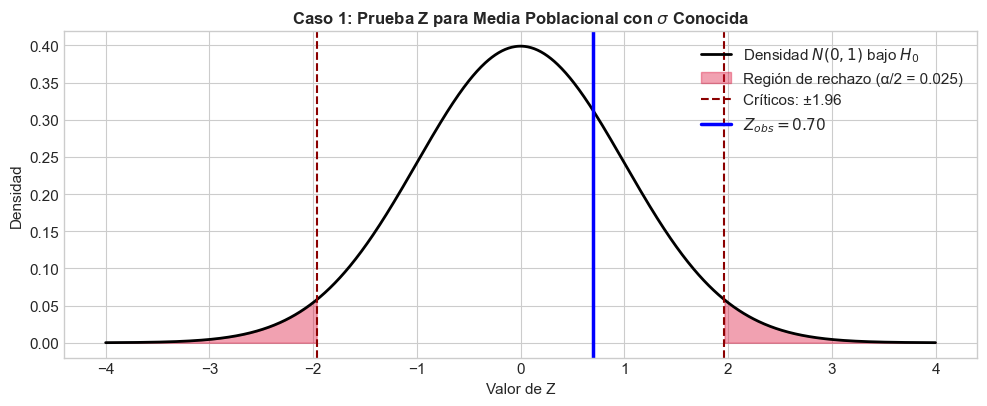

In [5]:
# Visualización gráfica de la distribución Z y la región de rechazo
fig, ax = plt.subplots(figsize=(10, 4.2))
x_plot = np.linspace(-4, 4, 1000)
y_plot = stats.norm.pdf(x_plot, 0, 1)

ax.plot(x_plot, y_plot, 'k-', lw=2, label='Densidad $N(0, 1)$ bajo $H_0$')

# Sombrear colas de rechazo
ax.fill_between(x_plot, 0, y_plot, where=(x_plot <= -z_critico), color='crimson', alpha=0.4, label=f'Región de rechazo (α/2 = {alpha_z/2})')
ax.fill_between(x_plot, 0, y_plot, where=(x_plot >= z_critico), color='crimson', alpha=0.4)

# Líneas críticas y Z observado
ax.axvline(-z_critico, color='darkred', linestyle='--', label=f'Críticos: ±{z_critico:.2f}')
ax.axvline(z_critico, color='darkred', linestyle='--')
ax.axvline(z_calc, color='blue', lw=2.5, linestyle='-', label=f'$Z_{{obs}} = {z_calc:.2f}$')

ax.set_title('Caso 1: Prueba Z para Media Poblacional con $\sigma$ Conocida')
ax.set_xlabel('Valor de Z')
ax.set_ylabel('Densidad')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 2. Media Poblacional con Desviación Estándar Desconocida ($\sigma$ desconocida) — Prueba $t$ de Student

### 2.1 Contexto del Problema e Hipótesis
Un equipo de ingeniería de frontend rediseñó el motor de renderizado de componentes. El tiempo de renderizado promedio histórico de la versión previa era de $\mu_0 = 85.0\text{ ms}$.

Para la nueva versión no se dispone de la varianza poblacional previa $\sigma^2$. Se recolecta una muestra aleatoria de $n = 35$ renderizados en producción y se estima la dispersión mediante la desviación estándar muestral $s$.

El equipo desea contrastar:
* **Hipótesis bilateral:** ¿Difiere la latencia promedio del valor de referencia?
  $$H_0: \mu = 85.0\text{ ms} \quad \text{vs.} \quad H_A: \mu \neq 85.0\text{ ms}$$
* **Hipótesis unilateral izquierda:** ¿Hay evidencia de que la latencia media disminuyó (mejora en rendimiento)?
  $$H_0: \mu = 85.0\text{ ms} \quad \text{vs.} \quad H_A: \mu < 85.0\text{ ms}$$

Nivel de significancia: $\alpha = 0.05$.


In [6]:
# Generación sintética del dataset para el Caso 2
np.random.seed(101)
n_t = 35
mu_0_t = 85.0

# Simulación: la nueva versión realmente promedia ~81.2 ms con desviación desconocida ~9.5 ms
tiempos_render = stats.norm.rvs(loc=81.2, scale=9.5, size=n_t, random_state=101)
df_t = pd.DataFrame({'tiempo_render_ms': tiempos_render})

xbar_t = df_t['tiempo_render_ms'].mean()
s_t = df_t['tiempo_render_ms'].std(ddof=1)
df_degrees = n_t - 1

print(f"--- Muestra Caso 2 (n = {n_t}, df = {df_degrees}) ---")
print(f"Media muestral (x̄):       {xbar_t:.4f} ms")
print(f"Desviación muestral (s):  {s_t:.4f} ms")


--- Muestra Caso 2 (n = 35, df = 34) ---
Media muestral (x̄):       83.3176 ms
Desviación muestral (s):  10.0238 ms


### 2.2 Cálculo "A Pie" (Paso a Paso)
Al desconocer $\sigma$, se utiliza la desviación muestral $s$ con $df = n - 1$ grados de libertad:
$$t_{\text{calc}} = \frac{\bar{x} - \mu_0}{\frac{s}{\sqrt{n}}} \sim t_{n-1}$$

* **Error estándar estimado**: $SE = \frac{s}{\sqrt{n}}$
* **Caso bilateral**:
  * Valores críticos: $\pm t_{1 - \alpha/2, n-1} = \pm \text{stats.t.ppf}(1 - \alpha/2, df)$
  * P-valor: $p = 2 \times P(t_{n-1} \ge |t_{\text{calc}}|) = 2 \times \text{stats.t.sf}(|t_{\text{calc}}|, df)$
* **Caso unilateral izquierdo**:
  * Valor crítico: $-t_{1 - \alpha, n-1} = \text{stats.t.ppf}(\alpha, df)$
  * P-valor: $p = P(t_{n-1} \le t_{\text{calc}}) = \text{stats.t.cdf}(t_{\text{calc}}, df)$


In [7]:
alpha_t = 0.05

# 1. Error estándar muestral
se_t = s_t / np.sqrt(n_t)

# 2. Estadístico t calculado
t_calc = (xbar_t - mu_0_t) / se_t

# 3. Valores críticos
t_crit_two = stats.t.ppf(1 - alpha_t / 2, df=df_degrees)
t_crit_less = -stats.t.ppf(1 - alpha_t, df=df_degrees)

# 4. P-valores exactos
p_val_t_two = 2 * stats.t.sf(abs(t_calc), df=df_degrees)
p_val_t_less = stats.t.cdf(t_calc, df=df_degrees)

print("=== CÁLCULO A PIE (PRUEBA t DE STUDENT) ===")
print(f"Error estándar estimado (s/√n): {se_t:.4f}")
print(f"t calculado (t_obs):             {t_calc:.4f}")
print(f"Bilateral  - Críticos: ±{t_crit_two:.4f} | P-valor: {p_val_t_two:.5f}")
print(f"Unilateral - Crítico:  {t_crit_less:.4f} | P-valor: {p_val_t_less:.5f}")

decision_t_two = "Rechazar H0" if abs(t_calc) > t_crit_two else "No rechazar H0"
decision_t_less = "Rechazar H0" if t_calc < t_crit_less else "No rechazar H0"
print(f"Decisión Bilateral  (α={alpha_t}): {decision_t_two}")
print(f"Decisión Unilateral (α={alpha_t}): {decision_t_less}")


=== CÁLCULO A PIE (PRUEBA t DE STUDENT) ===
Error estándar estimado (s/√n): 1.6943
t calculado (t_obs):             -0.9930
Bilateral  - Críticos: ±2.0322 | P-valor: 0.32775
Unilateral - Crítico:  -1.6909 | P-valor: 0.16387
Decisión Bilateral  (α=0.05): No rechazar H0
Decisión Unilateral (α=0.05): No rechazar H0


### 2.3 Uso de Funciones Predefinidas (`scipy.stats.ttest_1samp`)
La función oficial de SciPy es `scipy.stats.ttest_1samp`, la cual admite el parámetro `alternative` (`'two-sided'`, `'less'`, `'greater'`).


In [8]:
# Ejecución con scipy.stats.ttest_1samp
res_ttest_two = stats.ttest_1samp(df_t['tiempo_render_ms'], popmean=mu_0_t, alternative='two-sided')
res_ttest_less = stats.ttest_1samp(df_t['tiempo_render_ms'], popmean=mu_0_t, alternative='less')

tabla_t = pd.DataFrame({
    'Contraste': ['Bilateral (two-sided)', 'Unilateral izquierda (less)'],
    't (A pie)': [t_calc, t_calc],
    't (scipy.stats)': [res_ttest_two.statistic, res_ttest_less.statistic],
    'P-valor (A pie)': [p_val_t_two, p_val_t_less],
    'P-valor (scipy.stats)': [res_ttest_two.pvalue, res_ttest_less.pvalue],
    'Diferencia absoluta': [abs(p_val_t_two - res_ttest_two.pvalue), abs(p_val_t_less - res_ttest_less.pvalue)]
})
tabla_t


,Contraste,t (A pie),t (scipy.stats),P-valor (A pie),P-valor (scipy.stats),Diferencia absoluta
0,Bilateral (two-sided),-0.99296,-0.99296,0.32775,0.32775,0.0
1,Unilateral izquierda (less),-0.99296,-0.99296,0.16387,0.16387,0.0


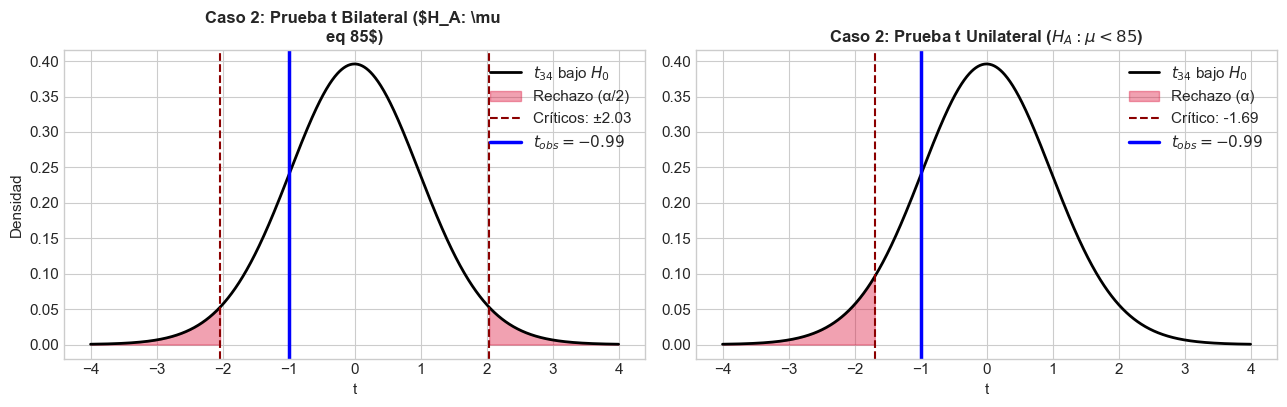

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
t_grid = np.linspace(-4, 4, 1000)
y_t_dens = stats.t.pdf(t_grid, df=df_degrees)

# Panel Bilateral
ax1.plot(t_grid, y_t_dens, 'k-', lw=2, label=f'$t_{{{df_degrees}}}$ bajo $H_0$')
ax1.fill_between(t_grid, 0, y_t_dens, where=(t_grid <= -t_crit_two), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax1.fill_between(t_grid, 0, y_t_dens, where=(t_grid >= t_crit_two), color='crimson', alpha=0.4)
ax1.axvline(-t_crit_two, color='darkred', linestyle='--')
ax1.axvline(t_crit_two, color='darkred', linestyle='--', label=f'Críticos: ±{t_crit_two:.2f}')
ax1.axvline(t_calc, color='blue', lw=2.5, label=f'$t_{{obs}} = {t_calc:.2f}$')
ax1.set_title('Caso 2: Prueba t Bilateral ($H_A: \mu \neq 85$)')
ax1.set_xlabel('t')
ax1.set_ylabel('Densidad')
ax1.legend()

# Panel Unilateral
ax2.plot(t_grid, y_t_dens, 'k-', lw=2, label=f'$t_{{{df_degrees}}}$ bajo $H_0$')
ax2.fill_between(t_grid, 0, y_t_dens, where=(t_grid <= t_crit_less), color='crimson', alpha=0.4, label='Rechazo (α)')
ax2.axvline(t_crit_less, color='darkred', linestyle='--', label=f'Crítico: {t_crit_less:.2f}')
ax2.axvline(t_calc, color='blue', lw=2.5, label=f'$t_{{obs}} = {t_calc:.2f}$')
ax2.set_title('Caso 2: Prueba t Unilateral ($H_A: \mu < 85$)')
ax2.set_xlabel('t')
ax2.legend()

plt.tight_layout()
plt.show()


---

## 3. Proporción Poblacional ($p$) — Prueba $Z$ para Proporciones

### 3.1 Contexto del Problema e Hipótesis
Un contrato de nivel de servicio (SLA) para una pasarela de pagos electrónicos estipula que la tasa de transacciones procesadas satisfactoriamente debe ser de al menos el $95\%$ ($p_0 = 0.95$).

El equipo de operaciones monitorea una muestra de $n = 500$ transacciones en hora de alta concurrencia y registra cuántas resultaron exitosas ($k$). Se contrastan las hipótesis:

$$H_0: p = 0.95$$
$$H_A: p \neq 0.95 \quad (\text{prueba bilateral})$$

(o la prueba unilateral de degradación $H_A: p < 0.95$). Nivel de significancia: $\alpha = 0.05$.

**Verificación de la condición de normalidad:**
* $n p_0 = 500 \times 0.95 = 475 \ge 5$
* $n (1 - p_0) = 500 \times 0.05 = 25 \ge 5$

La aproximación asintótica normal para la proporción es completamente válida.


In [10]:
# Generación sintética del dataset para el Caso 3
np.random.seed(42)
n_prop = 500
p_0 = 0.95

# Simulamos que la tasa real de éxito en esta ventana cayó al 92.4%
transacciones_exito = stats.bernoulli.rvs(p=0.924, size=n_prop, random_state=42)
df_prop = pd.DataFrame({'exito': transacciones_exito})

k_exitos = int(df_prop['exito'].sum())
p_gorro = k_exitos / n_prop

print(f"--- Muestra Caso 3 (n = {n_prop}) ---")
print(f"Transacciones exitosas (k): {k_exitos}")
print(f"Proporción muestral (p̂):    {p_gorro:.4f}")
print(f"Proporción bajo H0 (p0):    {p_0:.4f}")
print(f"Condición np0: {n_prop*p_0:.1f} >= 5 | n(1-p0): {n_prop*(1-p_0):.1f} >= 5")


--- Muestra Caso 3 (n = 500) ---
Transacciones exitosas (k): 457
Proporción muestral (p̂):    0.9140
Proporción bajo H0 (p0):    0.9500
Condición np0: 475.0 >= 5 | n(1-p0): 25.0 >= 5


### 3.2 Cálculo "A Pie" (Paso a Paso)
Bajo la hipótesis nula, el error estándar exacto se evalúa con el parámetro teórico $p_0$:
$$SE_0 = \sqrt{\frac{p_0 (1 - p_0)}{n}}$$

El estadístico de prueba es:
$$Z_{\text{calc}} = \frac{\hat{p} - p_0}{SE_0} = \frac{\hat{p} - p_0}{\sqrt{\frac{p_0(1-p_0)}{n}}} \sim N(0, 1)$$

* **Valor crítico bilateral**: $z_{\text{crit}} = \Phi^{-1}(1 - \alpha/2) = \text{stats.norm.ppf}(1 - \alpha/2)$
* **P-valor bilateral**: $p = 2 \times \text{stats.norm.sf}(|Z_{\text{calc}}|)$


In [11]:
alpha_prop = 0.05

# 1. Error estándar bajo H0
se_prop_0 = np.sqrt(p_0 * (1 - p_0) / n_prop)

# 2. Estadístico Z observado
z_prop_calc = (p_gorro - p_0) / se_prop_0

# 3. Valor crítico bilateral
z_crit_prop = stats.norm.ppf(1 - alpha_prop / 2)

# 4. P-valor bilateral
p_val_prop = 2 * stats.norm.sf(abs(z_prop_calc))

print("=== CÁLCULO A PIE (PRUEBA Z DE PROPORCIÓN) ===")
print(f"Error estándar teórico (SE0): {se_prop_0:.5f}")
print(f"Z calculado (Z_obs):          {z_prop_calc:.4f}")
print(f"Valor crítico bilateral:      ±{z_crit_prop:.4f}")
print(f"P-valor bilateral:            {p_val_prop:.6f}")

decision_prop = "Rechazar H0" if abs(z_prop_calc) > z_crit_prop else "No rechazar H0"
print(f"Decisión formal (α = {alpha_prop}): {decision_prop}")


=== CÁLCULO A PIE (PRUEBA Z DE PROPORCIÓN) ===
Error estándar teórico (SE0): 0.00975
Z calculado (Z_obs):          -3.6935
Valor crítico bilateral:      ±1.9600
P-valor bilateral:            0.000221
Decisión formal (α = 0.05): Rechazar H0


### 3.3 Uso de Funciones Predefinidas (`statsmodels` y `scipy.stats`)
1. **`statsmodels.stats.proportion.proportions_ztest`**:
   * Función estándar para proporciones.
   * **Detalle técnico fundamental**: Para que la varianza coincida con la fórmula canónica de libro de texto bajo $H_0$ ($\sqrt{p_0(1-p_0)/n}$), se debe especificar `prop_var=p_0`. Si se omite, calcula la varianza a partir de la proporción observada $\hat{p}$.
2. **`scipy.stats.binomtest`**:
   * Proporciona la prueba binomial exacta (sin aproximación normal), muy útil como estándar de oro.


In [12]:
# 1. statsmodels con varianza bajo H0 (fórmula estándar teórica)
z_sm_h0, p_sm_h0 = proportions_ztest(count=k_exitos, nobs=n_prop, value=p_0, prop_var=p_0, alternative='two-sided')

# 2. statsmodels con varianza empírica muestral
z_sm_samp, p_sm_samp = proportions_ztest(count=k_exitos, nobs=n_prop, value=p_0, alternative='two-sided')

# 3. scipy.stats prueba binomial exacta
res_binom = stats.binomtest(k=k_exitos, n=n_prop, p=p_0, alternative='two-sided')

tabla_prop = pd.DataFrame({
    'Método': [
        'A pie (fórmula teórica Z con p0)',
        'statsmodels proportions_ztest (prop_var=p0)',
        'statsmodels proportions_ztest (con p̂ muestral)',
        'scipy.stats.binomtest (prueba binomial exacta)'
    ],
    'Estadístico': [f"Z = {z_prop_calc:.4f}", f"Z = {z_sm_h0:.4f}", f"Z = {z_sm_samp:.4f}", f"k = {k_exitos}"],
    'P-valor': [p_val_prop, p_sm_h0, p_sm_samp, res_binom.pvalue],
    'Decisión (α=0.05)': [
        decision_prop,
        "Rechazar H0" if p_sm_h0 < alpha_prop else "No rechazar H0",
        "Rechazar H0" if p_sm_samp < alpha_prop else "No rechazar H0",
        "Rechazar H0" if res_binom.pvalue < alpha_prop else "No rechazar H0"
    ]
})
tabla_prop


,Método,Estadístico,P-valor,Decisión (α=0.05)
0,A pie (fórmula teórica Z con p0),Z = -3.6935,0.00022,Rechazar H0
1,statsmodels proportions_ztest (prop_var=p0),Z = -3.6935,0.00022,Rechazar H0
2,statsmodels proportions_ztest (con p̂ muestral),Z = -2.8712,0.00409,Rechazar H0
3,scipy.stats.binomtest (prueba binomial exacta),k = 457,0.00064,Rechazar H0


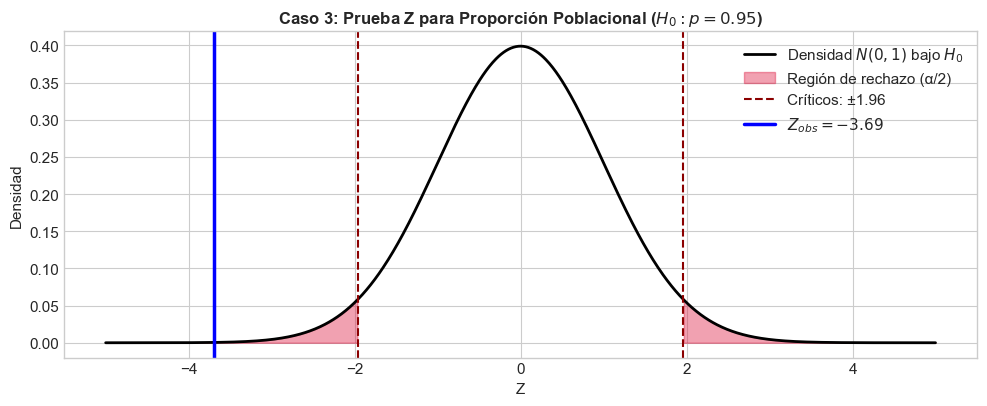

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
z_grid = np.linspace(-5, 5, 1000)
y_prop = stats.norm.pdf(z_grid, 0, 1)

ax.plot(z_grid, y_prop, 'k-', lw=2, label='Densidad $N(0, 1)$ bajo $H_0$')
ax.fill_between(z_grid, 0, y_prop, where=(z_grid <= -z_crit_prop), color='crimson', alpha=0.4, label='Región de rechazo (α/2)')
ax.fill_between(z_grid, 0, y_prop, where=(z_grid >= z_crit_prop), color='crimson', alpha=0.4)
ax.axvline(-z_crit_prop, color='darkred', linestyle='--', label=f'Críticos: ±{z_crit_prop:.2f}')
ax.axvline(z_crit_prop, color='darkred', linestyle='--')
ax.axvline(z_prop_calc, color='blue', lw=2.5, label=f'$Z_{{obs}} = {z_prop_calc:.2f}$')

ax.set_title('Caso 3: Prueba Z para Proporción Poblacional ($H_0: p = 0.95$)')
ax.set_xlabel('Z')
ax.set_ylabel('Densidad')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


---

## 4. Varianza Poblacional ($\sigma^2$) — Prueba $\chi^2$ (Chi-cuadrada)

### 4.1 Contexto del Problema e Hipótesis
En sistemas de procesamiento de datos en tiempo real (pipelines Kafka / Flink), la variabilidad en los tiempos de respuesta por lote (jitter) impacta la estabilidad de todo el flujo.

El estándar de diseño establece que la varianza del tiempo de procesamiento no debe superar $\sigma_0^2 = 25.0\text{ ms}^2$ (desviación estándar máxima admisible $\sigma_0 = 5.0\text{ ms}$).

Se recolecta una muestra de $n = 30$ lotes de procesamiento. El equipo desea contrastar:
* **Hipótesis unilateral derecha:** ¿Existe evidencia de que la varianza superó el umbral admisible?
  $$H_0: \sigma^2 = 25.0\text{ ms}^2 \quad \text{vs.} \quad H_A: \sigma^2 > 25.0\text{ ms}^2$$
* **Hipótesis bilateral:**
  $$H_0: \sigma^2 = 25.0\text{ ms}^2 \quad \text{vs.} \quad H_A: \sigma^2 \neq 25.0\text{ ms}^2$$

Nivel de significancia: $\alpha = 0.05$.

**Supuesto crítico:** La prueba de varianza para una población es altamente sensible al supuesto de normalidad de la variable. Es mandatorio verificar la normalidad (e.g. mediante Shapiro-Wilk) antes de confiar en las conclusiones de la prueba $\chi^2$.


In [14]:
# Generación sintética del dataset para el Caso 4
np.random.seed(77)
n_var = 30
sigma2_0 = 25.0      # Varianza objetivo bajo H0
df_chi = n_var - 1

# Simulamos tiempos con varianza real aumentada (sigma_real = 6.8 -> var ≈ 46.2)
tiempos_proc = stats.norm.rvs(loc=50.0, scale=6.8, size=n_var, random_state=77)
df_var = pd.DataFrame({'tiempo_proc_ms': tiempos_proc})

s2_muestral = df_var['tiempo_proc_ms'].var(ddof=1)
s_muestral = np.sqrt(s2_muestral)

# Validación de normalidad requerida
shapiro_stat, shapiro_p = stats.shapiro(df_var['tiempo_proc_ms'])

print(f"--- Muestra Caso 4 (n = {n_var}, df = {df_chi}) ---")
print(f"Varianza muestral (s²):      {s2_muestral:.4f} ms²")
print(f"Desviación muestral (s):     {s_muestral:.4f} ms")
print(f"Varianza de referencia (σ0²): {sigma2_0:.4f} ms²")
print(f"Test de Normalidad (Shapiro-Wilk): W = {shapiro_stat:.4f}, p = {shapiro_p:.4f} (> 0.05: Normalidad satisfecha)")


--- Muestra Caso 4 (n = 30, df = 29) ---
Varianza muestral (s²):      45.4956 ms²
Desviación muestral (s):     6.7450 ms
Varianza de referencia (σ0²): 25.0000 ms²
Test de Normalidad (Shapiro-Wilk): W = 0.9715, p = 0.5819 (> 0.05: Normalidad satisfecha)


### 4.2 Cálculo "A Pie" (Paso a Paso)
Bajo la hipótesis nula y suponiendo una población normal, la cantidad pivote sigue una distribución Ji-cuadrada ($\chi^2$) con $df = n - 1$ grados de libertad:
$$\chi^2_{\text{calc}} = \frac{(n - 1) s^2}{\sigma_0^2} \sim \chi^2_{n-1}$$

* **Unilateral derecha ($H_A: \sigma^2 > \sigma_0^2$)**:
  * Valor crítico: $\chi^2_{1 - \alpha, n-1} = \text{stats.chi2.ppf}(1 - \alpha, df)$
  * P-valor: $p = P(\chi^2_{n-1} \ge \chi^2_{\text{calc}}) = \text{stats.chi2.sf}(\chi^2_{\text{calc}}, df)$
* **Bilateral ($H_A: \sigma^2 \neq \sigma_0^2$)**:
  * Valores críticos: $\chi^2_{\alpha/2, n-1}$ y $\chi^2_{1 - \alpha/2, n-1}$
  * P-valor: $p = 2 \times \min\left(P(\chi^2 \le \chi^2_{\text{calc}}), P(\chi^2 \ge \chi^2_{\text{calc}})\right)$


In [15]:
alpha_chi = 0.05

# 1. Estadístico Chi-cuadrado calculado
chi2_calc = (df_chi * s2_muestral) / sigma2_0

# 2. Valores críticos
chi2_crit_greater = stats.chi2.ppf(1 - alpha_chi, df=df_chi)
chi2_crit_lower = stats.chi2.ppf(alpha_chi / 2, df=df_chi)
chi2_crit_upper = stats.chi2.ppf(1 - alpha_chi / 2, df=df_chi)

# 3. P-valores
p_val_chi_greater = stats.chi2.sf(chi2_calc, df=df_chi)
p_val_chi_two = 2 * min(stats.chi2.cdf(chi2_calc, df=df_chi), stats.chi2.sf(chi2_calc, df=df_chi))

print("=== CÁLCULO A PIE (PRUEBA CHI-CUADRADA DE VARIANZA) ===")
print(f"Chi² calculado (χ²_obs):     {chi2_calc:.4f}")
print(f"Unilateral derecha (α={alpha_chi}): Crítico = {chi2_crit_greater:.4f} | P-valor = {p_val_chi_greater:.5f}")
print(f"Bilateral (α={alpha_chi}):          Críticos = [{chi2_crit_lower:.4f}, {chi2_crit_upper:.4f}] | P-valor = {p_val_chi_two:.5f}")

decision_chi_greater = "Rechazar H0" if chi2_calc > chi2_crit_greater else "No rechazar H0"
print(f"Decisión Unilateral:         {decision_chi_greater}")


=== CÁLCULO A PIE (PRUEBA CHI-CUADRADA DE VARIANZA) ===
Chi² calculado (χ²_obs):     52.7749
Unilateral derecha (α=0.05): Crítico = 42.5570 | P-valor = 0.00446
Bilateral (α=0.05):          Críticos = [16.0471, 45.7223] | P-valor = 0.00892
Decisión Unilateral:         Rechazar H0


### 4.3 Uso de Función Predefinida / Empaquetada
En el ecosistema Python, `scipy.stats` no cuenta con una función unificada para la varianza muestral continua (la función `stats.chisquare` se enfoca en bondad de ajuste de frecuencias categóricas).

Por esta razón, empaquetamos una función estándar reusable `chi2_test_1samp_variance` con la interfaz habitual de SciPy para contrastar cualquier alternativa (`two-sided`, `greater`, `less`).


In [16]:
def chi2_test_1samp_variance(data, var_0, alternative='two-sided'):
    """Prueba de hipótesis Chi-cuadrada para la varianza de una población normal."""
    x = np.asarray(data)
    n = len(x)
    df = n - 1
    s2 = np.var(x, ddof=1)
    stat = (df * s2) / var_0
    
    if alternative == 'two-sided':
        pval = 2 * min(stats.chi2.cdf(stat, df), stats.chi2.sf(stat, df))
    elif alternative == 'greater':
        pval = stats.chi2.sf(stat, df)
    elif alternative == 'less':
        pval = stats.chi2.cdf(stat, df)
    else:
        raise ValueError("alternative debe ser 'two-sided', 'greater' o 'less'")
        
    return {'statistic': stat, 'pvalue': pval, 'df': df, 'sample_var': s2}

# Ejecución con la función empaquetada
res_chi_pkg_greater = chi2_test_1samp_variance(df_var['tiempo_proc_ms'], var_0=sigma2_0, alternative='greater')
res_chi_pkg_two = chi2_test_1samp_variance(df_var['tiempo_proc_ms'], var_0=sigma2_0, alternative='two-sided')

tabla_chi = pd.DataFrame({
    'Alternativa': ['Unilateral derecha (greater)', 'Bilateral (two-sided)'],
    'Chi² (A pie)': [chi2_calc, chi2_calc],
    'Chi² (Empaquetada)': [res_chi_pkg_greater['statistic'], res_chi_pkg_two['statistic']],
    'P-valor (A pie)': [p_val_chi_greater, p_val_chi_two],
    'P-valor (Empaquetada)': [res_chi_pkg_greater['pvalue'], res_chi_pkg_two['pvalue']],
    'Decisión (α=0.05)': [
        decision_chi_greater,
        "Rechazar H0" if p_val_chi_two < alpha_chi else "No rechazar H0"
    ]
})
tabla_chi


,Alternativa,Chi² (A pie),Chi² (Empaquetada),P-valor (A pie),P-valor (Empaquetada),Decisión (α=0.05)
0,Unilateral derecha (greater),52.77494,52.77494,0.00446,0.00446,Rechazar H0
1,Bilateral (two-sided),52.77494,52.77494,0.00892,0.00892,Rechazar H0


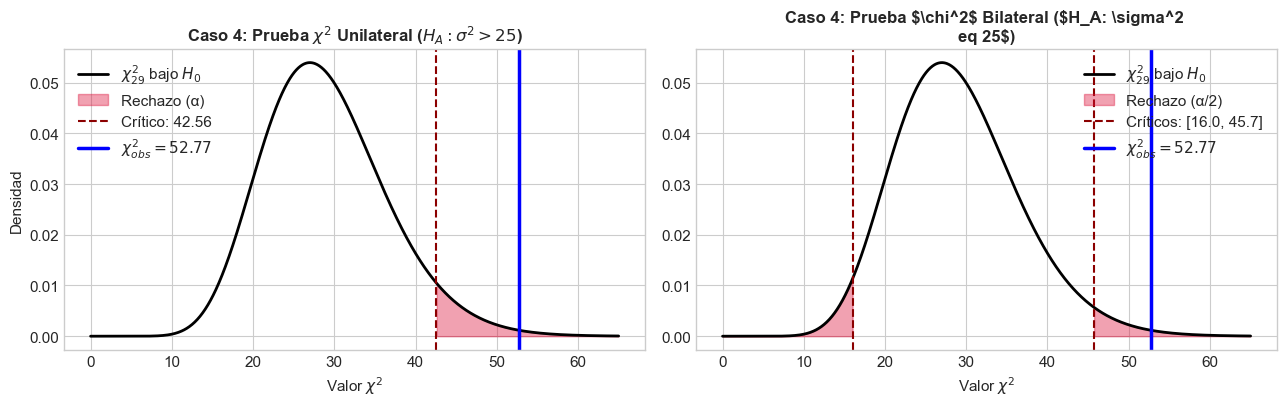

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
x_chi_grid = np.linspace(0, 65, 1000)
y_chi_dens = stats.chi2.pdf(x_chi_grid, df=df_chi)

# Panel Unilateral derecha
ax1.plot(x_chi_grid, y_chi_dens, 'k-', lw=2, label=f'$\chi^2_{{{df_chi}}}$ bajo $H_0$')
ax1.fill_between(x_chi_grid, 0, y_chi_dens, where=(x_chi_grid >= chi2_crit_greater), color='crimson', alpha=0.4, label='Rechazo (α)')
ax1.axvline(chi2_crit_greater, color='darkred', linestyle='--', label=f'Crítico: {chi2_crit_greater:.2f}')
ax1.axvline(chi2_calc, color='blue', lw=2.5, label=f'$\chi^2_{{obs}} = {chi2_calc:.2f}$')
ax1.set_title('Caso 4: Prueba $\chi^2$ Unilateral ($H_A: \sigma^2 > 25$)')
ax1.set_xlabel('Valor $\chi^2$')
ax1.set_ylabel('Densidad')
ax1.legend()

# Panel Bilateral
ax2.plot(x_chi_grid, y_chi_dens, 'k-', lw=2, label=f'$\chi^2_{{{df_chi}}}$ bajo $H_0$')
ax2.fill_between(x_chi_grid, 0, y_chi_dens, where=(x_chi_grid <= chi2_crit_lower), color='crimson', alpha=0.4, label='Rechazo (α/2)')
ax2.fill_between(x_chi_grid, 0, y_chi_dens, where=(x_chi_grid >= chi2_crit_upper), color='crimson', alpha=0.4)
ax2.axvline(chi2_crit_lower, color='darkred', linestyle='--')
ax2.axvline(chi2_crit_upper, color='darkred', linestyle='--', label=f'Críticos: [{chi2_crit_lower:.1f}, {chi2_crit_upper:.1f}]')
ax2.axvline(chi2_calc, color='blue', lw=2.5, label=f'$\chi^2_{{obs}} = {chi2_calc:.2f}$')
ax2.set_title('Caso 4: Prueba $\chi^2$ Bilateral ($H_A: \sigma^2 \neq 25$)')
ax2.set_xlabel('Valor $\chi^2$')
ax2.legend()

plt.tight_layout()
plt.show()


---

## 5. Tabla Resumen y Guía de Selección para Pruebas de Una Población

| Parámetro Poblacional | Hipótesis Nula ($H_0$) | Estadístico de Prueba | Distribución bajo $H_0$ | Cálculo "A Pie" (SciPy) | Función Predefinida / Estándar | Supuestos Clave |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Media con $\sigma$ conocida** | $\mu = \mu_0$ | $Z = \frac{\bar{x} - \mu_0}{\sigma / \sqrt{n}}$ | $N(0, 1)$ | `stats.norm.sf` / `ppf` | `ztest_1samp_known_sd` / `statsmodels.ztest` | Población normal o $n \ge 30$ (TLC). $\sigma$ debe ser conocida a priori. |
| **Media con $\sigma$ desconocida** | $\mu = \mu_0$ | $t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$ | $t_{n-1}$ | `stats.t.sf` / `ppf` | `scipy.stats.ttest_1samp` | Población aproximadamente normal o $n \ge 30$. Robusta ante desvíos moderados. |
| **Proporción ($p$)** | $p = p_0$ | $Z = \frac{\hat{p} - p_0}{\sqrt{p_0(1-p_0)/n}}$ | $N(0, 1)$ | `stats.norm.sf` / `ppf` | `statsmodels.stats.proportion.proportions_ztest` | $n p_0 \ge 5$ y $n(1-p_0) \ge 5$. Si no se cumple, usar `scipy.stats.binomtest`. |
| **Varianza ($\sigma^2$)** | $\sigma^2 = \sigma_0^2$ | $\chi^2 = \frac{(n-1)s^2}{\sigma_0^2}$ | $\chi^2_{n-1}$ | `stats.chi2.sf` / `ppf` | `chi2_test_1samp_variance` | **Normalidad estricta**. Muy sensible a violaciones de curtosis o asimetría. |

### Principios Fundamentales para la Práctica Profesional
1. **Definir la dirección de la hipótesis a priori**: La hipótesis alternativa (bilateral o unilateral) debe definirse **antes** de examinar los datos de la muestra, guiada exclusivamente por la pregunta de ingeniería o de negocio, evitando el sesgo de confirmación (*HARKing*).
2. **Equivalencia de criterios de decisión**: La regla de la región de rechazo ($|T_{\text{obs}}| > T_{\text{crit}}$) y la regla del p-valor ($p < \alpha$) son formalmente equivalentes y siempre conducen a la misma decisión; el p-valor además mide la fuerza de la evidencia contra $H_0$.
3. **Significancia estadística vs. significancia práctica**: Rechazar $H_0$ certifica que la diferencia no es atribuible a la casualidad del muestreo; no obstante, el equipo debe evaluar el tamaño del efecto (e.g. diferencia en milisegundos) para determinar si amerita cambios operacionales o inversiones en infraestructura.
